In [253]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch import nn
from PIL import Image
from torchvision.transforms import Compose, Resize, ToTensor, Normalize
import copy
from google.colab import files

In [254]:
X = torch.round(torch.tensor(np.random.uniform(high=5, low=0, size=(2, 3, 4, 4)), dtype=torch.float), decimals=1)
X


tensor([[[[4.4000, 3.2000, 3.9000, 3.0000],
          [0.3000, 1.8000, 1.4000, 4.8000],
          [2.7000, 0.4000, 4.6000, 4.2000],
          [3.7000, 0.5000, 1.5000, 1.9000]],

         [[4.9000, 0.6000, 3.2000, 2.7000],
          [2.3000, 3.9000, 2.9000, 2.0000],
          [1.0000, 5.0000, 4.8000, 0.4000],
          [1.0000, 1.6000, 3.1000, 2.2000]],

         [[3.4000, 0.7000, 2.5000, 3.9000],
          [3.5000, 4.1000, 3.1000, 2.2000],
          [3.2000, 4.3000, 1.1000, 0.1000],
          [4.8000, 3.0000, 1.7000, 3.6000]]],


        [[[2.9000, 3.7000, 2.4000, 0.7000],
          [4.7000, 2.1000, 0.7000, 3.1000],
          [1.0000, 0.0000, 2.4000, 4.2000],
          [4.6000, 2.8000, 1.4000, 5.0000]],

         [[0.4000, 2.2000, 2.6000, 1.3000],
          [2.0000, 0.5000, 1.9000, 2.4000],
          [1.4000, 3.5000, 2.1000, 0.4000],
          [2.8000, 4.4000, 0.2000, 1.2000]],

         [[4.5000, 0.9000, 4.0000, 2.5000],
          [4.1000, 4.3000, 2.0000, 0.8000],
          [1.5000, 3

In [255]:
batch_norm_2d = nn.BatchNorm2d(3)
y = batch_norm_2d(X)
batch_norm_2d.weight, batch_norm_2d.bias

(Parameter containing:
 tensor([1., 1., 1.], requires_grad=True),
 Parameter containing:
 tensor([0., 0., 0.], requires_grad=True))

In [256]:
torch.round(y[:, 0, :, :].mean(), decimals=1)

tensor(0., grad_fn=<RoundBackward1>)

In [257]:
layer_norm = nn.LayerNorm([3, 4, 4])
y = layer_norm(X)
layer_norm.weight, layer_norm.bias

(Parameter containing:
 tensor([[[1., 1., 1., 1.],
          [1., 1., 1., 1.],
          [1., 1., 1., 1.],
          [1., 1., 1., 1.]],
 
         [[1., 1., 1., 1.],
          [1., 1., 1., 1.],
          [1., 1., 1., 1.],
          [1., 1., 1., 1.]],
 
         [[1., 1., 1., 1.],
          [1., 1., 1., 1.],
          [1., 1., 1., 1.],
          [1., 1., 1., 1.]]], requires_grad=True),
 Parameter containing:
 tensor([[[0., 0., 0., 0.],
          [0., 0., 0., 0.],
          [0., 0., 0., 0.],
          [0., 0., 0., 0.]],
 
         [[0., 0., 0., 0.],
          [0., 0., 0., 0.],
          [0., 0., 0., 0.],
          [0., 0., 0., 0.]],
 
         [[0., 0., 0., 0.],
          [0., 0., 0., 0.],
          [0., 0., 0., 0.],
          [0., 0., 0., 0.]]], requires_grad=True))

In [258]:
torch.round(y[0, :, :, :].mean(), decimals=2)

tensor(0., grad_fn=<RoundBackward1>)

One gamma and beta tensor( where each element gamma scalar for those corresponding pixel value) for every  image..

In [259]:
gn = nn.GroupNorm(num_groups=1, num_channels=3)
y = gn(X)
gn.weight

Parameter containing:
tensor([1., 1., 1.], requires_grad=True)

In [260]:
torch.round(y[0, :, :, :].mean(), decimals=2)

tensor(0., grad_fn=<RoundBackward1>)

Saving images.jpg to images (6).jpg
(315, 160)


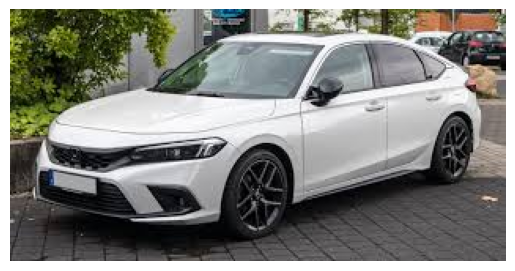

In [261]:
uploaded = files.upload()

filename = next(iter(uploaded))

img = Image.open(filename)
print(img.size)
plt.imshow(img)
plt.axis('off')
plt.show()


In [262]:
transform = Compose([
    ToTensor()
])
img = transform(img)
print(img.shape)


torch.Size([3, 160, 315])


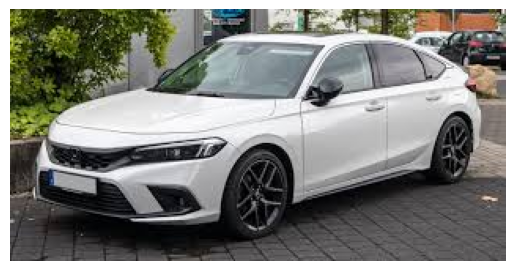

In [263]:
img = torch.permute(img, (1, 2, 0))
plt.imshow(img)
plt.axis('off')
plt.show()

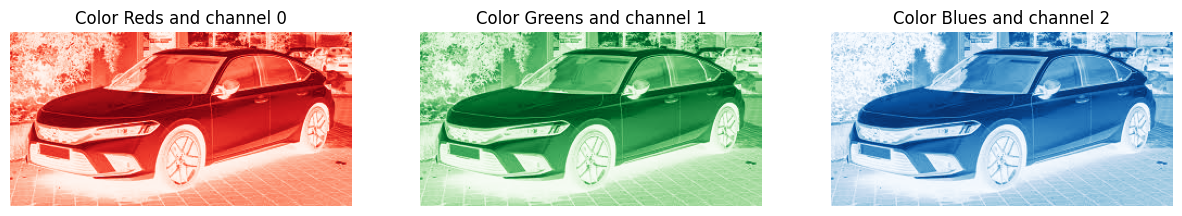

In [264]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for i, c in zip(range(3), ['Reds', 'Greens', 'Blues']):
  ax[i].imshow(img[:, :, i], cmap=c)
  ax[i].set_title(f'Color {c} and channel {i}')
  ax[i].axis('off')
plt.show()

In [265]:
print("Red mean:  ", img[:, :, 0].mean().item())
print("Green mean:", img[:, :, 1].mean().item())
print("Blue mean: ", img[:, :, 2].mean().item())


Red mean:   0.4537935256958008
Green mean: 0.45704570412635803
Blue mean:  0.4353170394897461


Saving cat.jpg to cat (1).jpg
(549, 364)


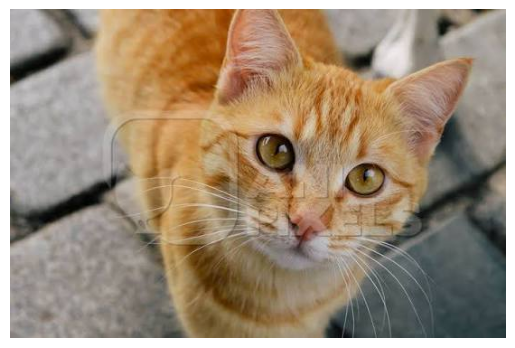

In [266]:
uploaded = files.upload()

filename = next(iter(uploaded))

img = Image.open(filename)
print(img.size)
plt.imshow(img)
plt.axis('off')
plt.show()


In [267]:
transform = Compose([
    ToTensor()
])
img = transform(img)
print(img.shape)


torch.Size([3, 364, 549])


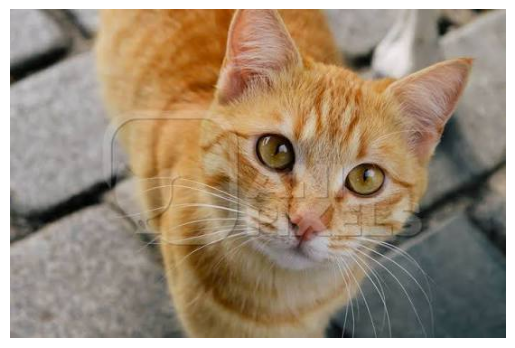

In [268]:
img = torch.permute(img, (1, 2, 0))
plt.imshow(img)
plt.axis('off')
plt.show()

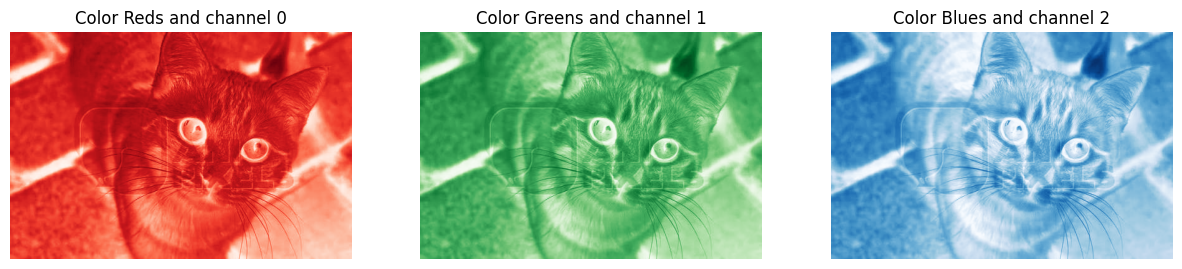

In [269]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for i, c in zip(range(3), ['Reds', 'Greens', 'Blues']):
  ax[i].imshow(img[:, :, i], cmap=c)
  ax[i].set_title(f'Color {c} and channel {i}')
  ax[i].axis('off')
plt.show()

In [270]:
print("Red mean:  ", img[:, :, 0].mean().item())
print("Green mean:", img[:, :, 1].mean().item())
print("Blue mean: ", img[:, :, 2].mean().item())


Red mean:   0.5827379822731018
Green mean: 0.5049468278884888
Blue mean:  0.41282522678375244


Early stopping at epoch 105
Loss: 0.02681008353829384
Loss previous 5 [0.030241195112466812, 0.029324498027563095, 0.028448492288589478, 0.027611244469881058, 0.02681008353829384]


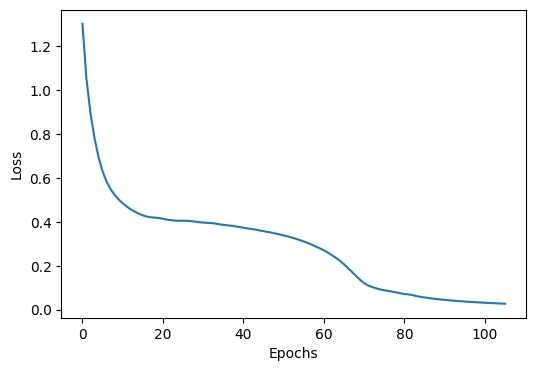

In [271]:
# Gradient Clipping

X = torch.tensor([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=torch.float)
y = torch.tensor([0, 1, 1, 0], dtype=torch.float).unsqueeze(1)
loss_function = nn.BCELoss()
epochs = 100

def init(m):
  if isinstance(m, nn.Linear):
    nn.init.kaiming_normal_(m.weight, mode='fan_in', nonlinearity='relu')
    if m.bias is not None:
      nn.init.zeros_(m.bias)

class MLP(nn.Module):
  def __init__(self):
    super().__init__()
    self.layers = nn.Sequential(
        nn.Linear(2, 8, bias=False),
        nn.LayerNorm(8),
        nn.ReLU(),
        nn.Linear(8, 4, bias=False),
        nn.LayerNorm(4),
        nn.ReLU(),
        nn.Linear(4, 1, bias=True),
        nn.Sigmoid()
    )
  def forward(self, x):
    return self.layers(x)

  def train(self, X, y, epochs):
    early_stopping = 5
    warning = 0
    tol = 0.001
    optimizer = torch.optim.Adam(self.parameters(), lr=1e-2)
    train_loss = []
    loss_function = nn.BCELoss()
    for epoch in range(epochs):
      optimizer.zero_grad()
      y_pred = self.forward(X)
      loss = loss_function(y_pred, y)
      loss.backward()
      optimizer.step()
      train_loss.append(loss.item())
      if len(train_loss) >= 2 and (train_loss[-2] - train_loss[-1]) < tol:
        warning += 1
      else:
        warning = 0
      if warning == early_stopping:
        print(f'Early stopping at epoch {epoch}')
        print(f'Loss: {loss.item()}')
        print(f'Loss previous 5 {train_loss[-5:]}')
        break

    plt.figure(figsize=(6, 4))
    plt.plot(train_loss)
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.show()
    return train_loss
model = MLP()
model.apply(init)
history = model.train(X, y, 750)


In [272]:
len(history)

106

isinstance() is a built-in Python function that checks whether an object belongs to a specific class or data type, returning True or False

In [133]:
with torch.inference_mode():
  print(model(X))

tensor([[0.2756],
        [0.8368],
        [0.5878],
        [0.2613]])


In [113]:
X = torch.arange(8, dtype=torch.float).reshape(2, 4)
X

tensor([[0., 1., 2., 3.],
        [4., 5., 6., 7.]])

In [115]:
layer_norm = nn.LayerNorm(4)
y =layer_norm(X)
y

tensor([[-1.3416, -0.4472,  0.4472,  1.3416],
        [-1.3416, -0.4472,  0.4472,  1.3416]],
       grad_fn=<NativeLayerNormBackward0>)

In [116]:
y[0].mean()

tensor(0., grad_fn=<MeanBackward0>)

In [117]:
y[:, 0].mean()

tensor(-1.3416, grad_fn=<MeanBackward0>)

In [118]:
batch_norm = nn.BatchNorm1d(2)
y = batch_norm(X.T)
y

tensor([[-1.3416, -1.3416],
        [-0.4472, -0.4472],
        [ 0.4472,  0.4472],
        [ 1.3416,  1.3416]], grad_fn=<NativeBatchNormBackward0>)

In [122]:
arr = np.array([0.9, 0.4, 0.3, 0.2, 0.1,])
for i in range(5):
  if arr[] > arr[-1] :
    print(True)

True
True
True
True
True


In [152]:
weight = nn.Parameter(torch.linspace(-2, 4, 4).reshape(2, 2))
print(weight)
weight_2 = (weight*2.51)/1.24
loss = weight_2.sum()
loss.backward()
print("Before clipping, gradient is:", weight.grad)
nn.utils.clip_grad_value_(weight, clip_value=1.0)
print("After clipping, gradient is:", weight.grad)

Parameter containing:
tensor([[-2.,  0.],
        [ 2.,  4.]], requires_grad=True)
Before clipping, gradient is: tensor([[2.0242, 2.0242],
        [2.0242, 2.0242]])
After clipping, gradient is: tensor([[1., 1.],
        [1., 1.]])


A gradient clipping by value clips every gradient element  in a tensor by clipping value.


Gradient Vector direction is lost

In [146]:
loss

tensor(3548.8972, grad_fn=<SumBackward0>)

In [164]:
linear = nn.Linear(5, 3)
torch.linalg.matrix_norm(linear.weight, ord='fro')

tensor(0.9458, grad_fn=<LinalgVectorNormBackward0>)

In [165]:
torch.linalg.matrix_norm(linear.weight, ord=2)

tensor(0.7331, grad_fn=<AmaxBackward0>)

In [166]:
torch.linalg.svd(linear.weight, full_matrices=False)[1]

tensor([0.7331, 0.5596, 0.2096], grad_fn=<LinalgSvdBackward0>)

For every gradient tesnor pytorch computes forb norm ( of a matrix not a tensor a layer of matrix) then for every forb norm of matrix, it takes l2 norm of all forb norm of a matrix, which is our total norm,

the max_norm where we defines, if total_norm <= max_norm then no clipping
otherwise clippign is done via coeffecient = max_norm/total_norm mulitplication via every element in a gradient tensor

The max norm has to be tuned, neither we know the total_norm or max_norm but defautl max_norm is 1


In [224]:
X = torch.tensor([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=torch.float)
y = torch.tensor([0, 1, 1, 0], dtype=torch.float).unsqueeze(1)

loss_function = nn.BCELoss()
epochs = 100

class MLP(nn.Module):
  def __init__(self):
    super().__init__()
    self.layers = nn.Sequential(
        nn.Linear(2, 8),
        nn.ReLU(),
        nn.Linear(8, 4),
        nn.ReLU(),
        nn.Linear(4, 1, bias=True),
        nn.Sigmoid()
    )
  def forward(self, x):
    return self.layers(x)




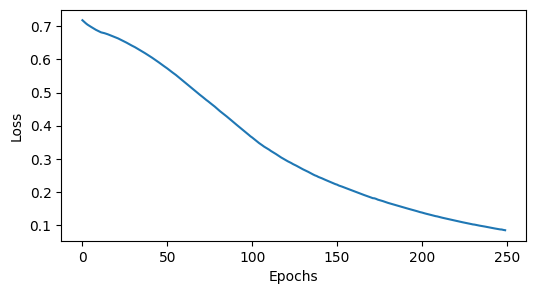

In [249]:
fig, ax = plt.subplots(1, 1, figsize=(6, 3))

model = MLP()
train_loss_1 = []
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

for i in range(250):
  optimizer.zero_grad()
  y_pred = model(X)
  loss = loss_function(y_pred, y)
  loss.backward()
  nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.0000001)
  optimizer.step()
  train_loss_1.append(loss.item())

ax.plot(train_loss_1)
ax.set_xlabel('Epochs')
ax.set_ylabel('Loss')

plt.show()


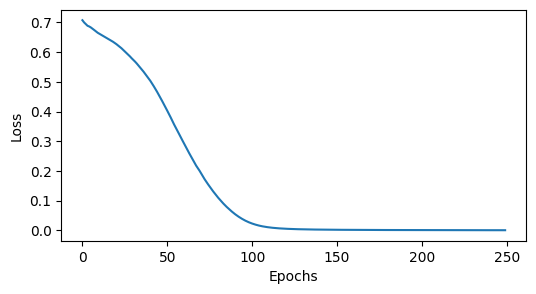

In [250]:
fig, ax = plt.subplots(1, 1, figsize=(6, 3))

model = MLP()
train_loss_1 = []
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

for i in range(250):
  optimizer.zero_grad()
  y_pred = model(X)
  loss = loss_function(y_pred, y)
  loss.backward()
  nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.1)
  optimizer.step()
  train_loss_1.append(loss.item())

ax.plot(train_loss_1)
ax.set_xlabel('Epochs')
ax.set_ylabel('Loss')

plt.show()


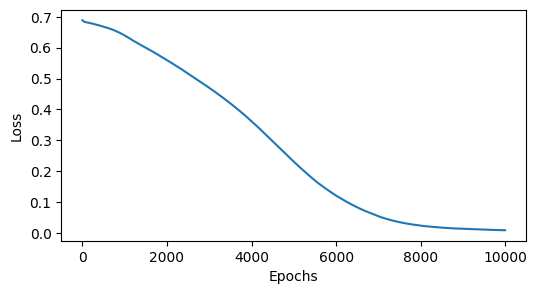

In [243]:
fig, ax = plt.subplots(1, 1, figsize=(6, 3))

model = MLP()
train_loss_1 = []
optimizer = torch.optim.SGD(model.parameters(), lr=1e-2)

for i in range(10000):
  optimizer.zero_grad()
  y_pred = model(X)
  loss = loss_function(y_pred, y)
  loss.backward()
  nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.1)
  optimizer.step()
  train_loss_1.append(loss.item())

ax.plot(train_loss_1)
ax.set_xlabel('Epochs')
ax.set_ylabel('Loss')

plt.show()


0.10598237812519073
0.10579090565443039
0.10559956729412079
0.1054084375500679
0.10521744936704636
0.10502661019563675
0.10483593493700027
0.10464540123939514
0.10445510596036911
0.10426490753889084


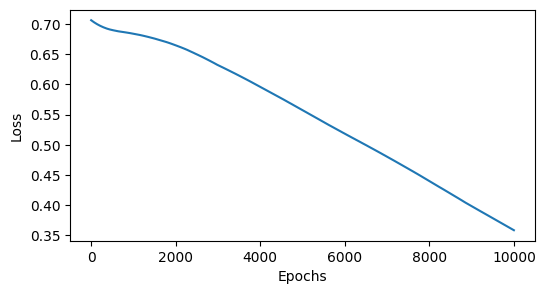

In [247]:
fig, ax = plt.subplots(1, 1, figsize=(6, 3))

model = MLP()
train_loss_1 = []
optimizer = torch.optim.SGD(model.parameters(), lr=1e-2)

for i in range(10000):
  optimizer.zero_grad()
  y_pred = model(X)
  loss = loss_function(y_pred, y)
  loss.backward()
  norm = nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.05)
  if i < 10:
    print(norm.item())
  optimizer.step()
  train_loss_1.append(loss.item())

ax.plot(train_loss_1)
ax.set_xlabel('Epochs')
ax.set_ylabel('Loss')

plt.show()
